# Chemistry transformer
We will use a transformer model to predict solubility from SMILES sequence

# Install Packages
Only run if you do not have packages installed

In [ ]:
%pip install rdkit
%pip install pandas
%pip install scikit-learn
%pip install matplotlib
%pip install torch torchvision torchaudio #note this will install pytorch for CPU


# Load data

In [6]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv("delaney.csv")
train_df, val_df = train_test_split(
    df, test_size=0.2, random_state=42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cpu


# Create vocabulary for SMILES
We need to identify the characters present in SMILES so the model knows what charcters to expect. We will create a tokenizer where it recognizes two character atom symbols as a single token. Other common characters in SMILES will also be recognized.
Note that if your testing set has characters not present in training set it will map to an unkown (UNK) character, performance might be bad if unknown characters are common.

In [7]:
import re

#this pattern defines what characters will be recognized as smiles tokens
#bracketed atoms which indicate charged functional group or other bracketed atoms and two character atoms will be grouped
SMILES_PATTERN = re.compile(
    r"(\[[^\[\]]+\]"        # Bracketed atoms
    r"|Br|Cl"               # Common two-character atoms
    r"|se|as"               # Aromatic two-character atoms
    r"|[BCNOPSFI]"          # Unbracketed aliphatic atoms
    r"|[bcnops]"            # Aromatic atoms
    r"|%\d{2,}"             # Multi-digit ring numbers
    r"|\d"                  # Single-digit ring numbers
    r"|[-=#$:/\\.@+*~?]"   # Bonds and other symbols
    r"|[()]"
    r")"
)

#tokenizes the smiles
def tokenize_smiles(smiles):
    tokens = []
    pos = 0

    for match in SMILES_PATTERN.finditer(smiles):
        # Handle unrecognized characters before this match
        if match.start() > pos:
            tokens.extend(["<UNK>"] * (match.start() - pos))

        tokens.append(match.group())
        pos = match.end()

    # Handle unrecognized characters at the end
    if pos < len(smiles):
        tokens.extend(["<UNK>"] * (len(smiles) - pos))

    return tokens

#builds the vocabulary from a dataframe
def build_vocab(df, smiles_col="SMILES"):
    """
    Build a token-to-ID vocabulary from a DataFrame containing SMILES strings.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing SMILES strings.
    smiles_col : str
        Name of the column containing SMILES strings.

    Returns
    -------
    dict
        Dictionary mapping tokens to integer IDs.
    """

    special_tokens = ["<PAD>", "<UNK>"]

    all_tokens = set()

    for smiles in df[smiles_col].dropna():
        all_tokens.update(tokenize_smiles(str(smiles)))

    # Exclude special tokens to avoid duplicates
    all_tokens.difference_update(special_tokens)

    vocab = special_tokens + sorted(all_tokens)

    token_to_id = {token: i for i, token in enumerate(vocab)}

    return token_to_id


def encode_smiles(smiles, token_to_id, max_length=None):
    tokens = tokenize_smiles(smiles)

    ids = [
        token_to_id.get(token, token_to_id["<UNK>"])
        for token in tokens
    ]

    if max_length is not None:
        if len(ids) > max_length:
            raise ValueError("SMILES exceeds max_length")

        ids += [token_to_id["<PAD>"]] * (max_length - len(ids))

    return ids

def encode_dataframe(df, token_to_id, max_length, smiles_col="SMILES"):
    df = df.copy()

    df["length"] = df[smiles_col].apply(
        lambda smi: len(tokenize_smiles(smi))
    )
    
    # Remove rows where SMILES exceeds max_length
    df = df[df["length"] <= max_length].copy()

    df["encoded"] = df[smiles_col].apply(
        lambda smi: encode_smiles(
            smi,
            token_to_id,
            max_length=max_length
        )
    )

    return df

token_to_id = build_vocab(train_df, smiles_col="SMILES")

#print the vocab size and the dictionary of ids
vocab_size = len(token_to_id)
print("Vocabulary size:", vocab_size)
print(token_to_id)

#apply the tokenization to the validation set
max_length = train_df["SMILES"].apply(
    lambda smi: len(tokenize_smiles(smi))
).max()

print("Maximum sequence length:", max_length)

train_df = encode_dataframe(
    train_df, token_to_id, max_length
)

val_df = encode_dataframe(
    val_df, token_to_id, max_length
)


Vocabulary size: 30
{'<PAD>': 0, '<UNK>': 1, '#': 2, '(': 3, ')': 4, '/': 5, '1': 6, '2': 7, '3': 8, '4': 9, '5': 10, '6': 11, '7': 12, '8': 13, '=': 14, 'Br': 15, 'C': 16, 'Cl': 17, 'F': 18, 'I': 19, 'N': 20, 'O': 21, 'P': 22, 'S': 23, '[nH]': 24, '\\': 25, 'c': 26, 'n': 27, 'o': 28, 's': 29}
Maximum sequence length: 98


# Make data into tensors for pytorch
Make the tensors and then the dataloaders for pytorch

In [8]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Training data
X_train = torch.tensor(
    train_df["encoded"].tolist(),
    dtype=torch.long
)

lengths_train = torch.tensor(
    train_df["length"].to_numpy(),
    dtype=torch.long
)

y_train = torch.tensor(
    train_df["measured log(solubility:mol/L)"].to_numpy(),
    dtype=torch.float32
).unsqueeze(1)

# Test data
X_val = torch.tensor(
    val_df["encoded"].tolist(),
    dtype=torch.long
)

lengths_val = torch.tensor(
    val_df["length"].to_numpy(),
    dtype=torch.long
)

y_val = torch.tensor(
    val_df["measured log(solubility:mol/L)"].to_numpy(),
    dtype=torch.float32
).unsqueeze(1)

train_dataset = TensorDataset(
    X_train, lengths_train, y_train
)

val_dataset = TensorDataset(
    X_val, lengths_val, y_val
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

# Transformer Model
We will set up a transformer with self-attention and encoding of token order. An attention mask will be applied to padded sequences to avoid attention with padded positions. Non-padded tokens will be pooled to be input for regression

In [9]:
# Transformer encoder for SMILES regression (replaces the LSTM)
class SmilesTransformerRegressor(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=64,
        hidden_dim=128,
        num_layers=1,
        dropout=0.2,
        pad_idx=0,
        num_heads=4,
        max_length=200
    ):
        super().__init__()

        # Learned token and positional embeddings; positions let attention model SMILES order
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        #each position gets its own learned embedding in this type of positional encoding
        self.position_embedding = nn.Embedding(max_length, embedding_dim)
        self.pad_idx = pad_idx

        # Each encoder layer contains multi-head self-attention and a feedforward network
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dim_feedforward=hidden_dim,
            dropout=dropout,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers,
                                                  enable_nested_tensor=False)
        
        #note if we use num_layers > 1 each layer will be initialized with the same parameters
        #it can be better to have different parameters so we can reset them all using this loop
        for layer in self.transformer.layers:
            for param in layer.parameters():
                if param.dim() > 1:
                    nn.init.xavier_uniform_(param)

        # Regression head
        self.regressor = nn.Sequential(
            nn.Linear(embedding_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x, lengths):
        # x shape: (batch, seq_len); lengths contains non-padding sequence lengths
        batch_size, seq_len = x.shape
        positions = torch.arange(seq_len, device=x.device).unsqueeze(0)
        #embedding is sum of token embedding and position embedding
        embedded = self.embedding(x) + self.position_embedding(positions)

        # True denotes padding that must not be attended to
        padding_mask = x.eq(self.pad_idx)
        encoded = self.transformer(embedded, src_key_padding_mask=padding_mask)

        # Mean-pool non-padding tokens to obtain one vector per SMILES
        valid_mask = (~padding_mask).unsqueeze(-1)
        pooled = (encoded * valid_mask).sum(dim=1) / lengths.clamp(min=1).unsqueeze(1)
        return self.regressor(pooled)


# Try adjusting embedding dimension, feedforward hidden dimension, encoder layers,
# and number of attention heads. embedding_dim must be divisible by num_heads.
model = SmilesTransformerRegressor(
    vocab_size=vocab_size,
    embedding_dim=64,
    hidden_dim=128,
    num_layers=1,
    dropout=0.2,
    pad_idx=token_to_id["<PAD>"],
    num_heads=4,
    max_length=max_length
).to(DEVICE)

criterion = nn.MSELoss() #MSELoss for regression
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


def run_epoch(model, train_loader, val_loader, criterion, optimizer): 
    total_loss = 0.0
    train_preds = []
    train_true = []
    
    model.train()
    for x, lengths, y in train_loader:
        x = x.to(DEVICE)
        lengths = lengths.to(DEVICE)
        y = y.to(DEVICE)

        optimizer.zero_grad()

        preds = model(x, lengths)
        loss = criterion(preds, y)

        
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        train_preds.extend(preds.cpu().detach().numpy())
        train_true.extend(y.cpu().numpy())

    
    train_rmse = np.sqrt(mean_squared_error(train_true, train_preds))
    train_r2 = r2_score(train_true, train_preds)
    train_avg_loss = total_loss / len(train_loader.dataset)
    
    val_preds = []
    val_true = []
    model.eval()
    with torch.no_grad():
        for x, lengths, y in val_loader:
            x = x.to(DEVICE)
            lengths = lengths.to(DEVICE)
            y = y.to(DEVICE)
            
            preds = model(x, lengths)
            val_preds.extend(preds.cpu().detach().numpy())
            val_true.extend(y.cpu().numpy())
    val_rmse = np.sqrt(mean_squared_error(val_true, val_preds))
    val_r2 = r2_score(val_true, val_preds)
    
    return train_avg_loss, train_rmse, train_r2, val_rmse, val_r2


#train model
num_epochs = 30

for epoch in range(1, num_epochs + 1):
    train_loss, train_rmse, train_r2, val_rmse, val_r2 = run_epoch(model, train_loader, val_loader, criterion, optimizer)
    

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | Train RMSE: {train_rmse:.4f} | Train R2: {train_r2:.4f} | "
        f"Val RMSE: {val_rmse:.4f} | Val R2: {val_r2:.4f}"
    )



Epoch 01 | Train Loss: 6.6537 | Train RMSE: 2.5795 | Train R2: -0.5124 | Val RMSE: 2.1397 | Val R2: -0.0514
Epoch 02 | Train Loss: 3.5270 | Train RMSE: 1.8780 | Train R2: 0.1983 | Val RMSE: 1.7362 | Val R2: 0.3078
Epoch 03 | Train Loss: 2.0325 | Train RMSE: 1.4256 | Train R2: 0.5380 | Val RMSE: 1.2423 | Val R2: 0.6456
Epoch 04 | Train Loss: 1.2015 | Train RMSE: 1.0961 | Train R2: 0.7269 | Val RMSE: 1.0657 | Val R2: 0.7392
Epoch 05 | Train Loss: 0.9801 | Train RMSE: 0.9900 | Train R2: 0.7772 | Val RMSE: 0.9976 | Val R2: 0.7715
Epoch 06 | Train Loss: 1.0120 | Train RMSE: 1.0060 | Train R2: 0.7700 | Val RMSE: 1.0063 | Val R2: 0.7674
Epoch 07 | Train Loss: 0.7930 | Train RMSE: 0.8905 | Train R2: 0.8197 | Val RMSE: 0.8981 | Val R2: 0.8148
Epoch 08 | Train Loss: 0.7075 | Train RMSE: 0.8411 | Train R2: 0.8392 | Val RMSE: 1.0363 | Val R2: 0.7534
Epoch 09 | Train Loss: 0.7633 | Train RMSE: 0.8737 | Train R2: 0.8265 | Val RMSE: 1.1736 | Val R2: 0.6837
Epoch 10 | Train Loss: 0.6816 | Train RMSE: 

# Validation set evaluation

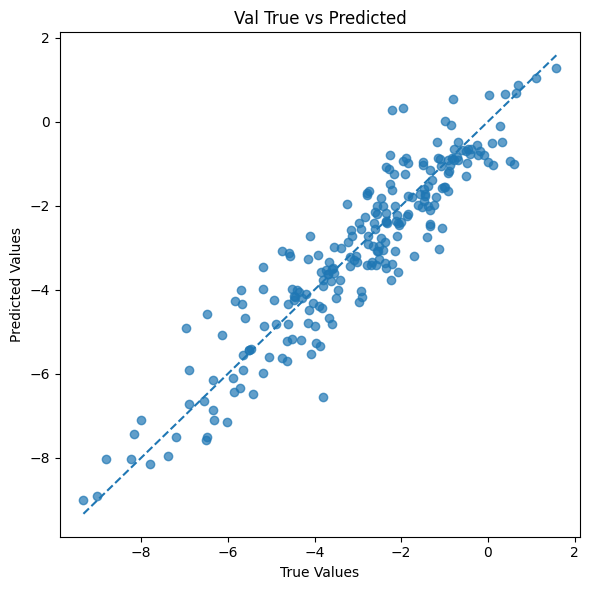

In [10]:
import matplotlib.pyplot as plt

#get the actual predictions
all_preds = []
all_true = []
model.eval()
for x, lengths, y in val_loader:
    x = x.to(DEVICE)
    lengths = lengths.to(DEVICE)
    y = y.to(DEVICE)
    with torch.no_grad():
        preds = model(x, lengths)
    
    all_preds.extend(preds.cpu().detach().numpy())
    all_true.extend(y.cpu().numpy())

plt.figure(figsize=(6, 6))
plt.scatter(all_true, all_preds, alpha=0.7)

min_val = min(min(all_true), min(all_preds))
max_val = max(max(all_true), max(all_preds))
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

plt.xlabel("True Values")
plt.ylabel("Predicted Values")
plt.title(f"Val True vs Predicted")
plt.tight_layout()
plt.show()
